# Monte Carlo — Bromo annual-mean visitor and modeled cultural thresholds

**Executed reproducibility notebook.** This is an **assumption-conditioned stress test** of approved Figures 6a and 8b, not a validated or original fully coupled seven-subsystem model. The independent triangular/uniform input distributions have **not** been fitted to observed Bromo parameter distributions.

10,000 independent draws, fixed seed 20261113. Model period 2025–2045. Visitor first-passage uses annual-average admissions/day ≥2,752; cultural threshold is year-end model index <60. Draws without a crossing through 2045 are reported separately (coded -1). The cultural index and visitor counts are distinct scenario indicators; no ecological-health 80% event is simulated.


In [1]:
from pathlib import Path
import sys
cwd=Path.cwd().resolve()
root=next((p for p in (cwd,*cwd.parents) if (p/'reproducibility/scripts/bromo_monte_carlo_assumptions.py').is_file()),None)
assert root is not None,'Run from research package/repo'
sys.path.insert(0,str(root/'reproducibility/scripts'))
from bromo_monte_carlo_assumptions import simulate, describe, plot_envelopes
N,SEED=10000,20261113
output=root/'reproducibility/outputs/monte-carlo-2026-11-13'
output.mkdir(parents=True,exist_ok=True)
print('Executing 10,000 assumption-conditioned triangular Monte Carlo draws ...')
draws, trajectories=simulate(N, SEED, distribution='triangular')
summary=describe(draws)
for label, result in summary.items():print(label,result)
plot_envelopes(trajectories,output/'assumption_conditioned_mc_envelopes.png')


Executing 10,000 assumption-conditioned triangular Monte Carlo draws ...


bau_visitor {'n': 10000, 'crossed_by_2045': 10000, 'not_crossed_by_2045': 0, 'crossing_share_pct': 100.0, 'crossing_year_p05_conditional': 2039.0, 'crossing_year_median_conditional': 2040.0, 'crossing_year_p95_conditional': 2042.0, 'earliest_crossing_year': 2039, 'latest_crossing_year': 2042}
intervention_visitor {'n': 10000, 'crossed_by_2045': 824, 'not_crossed_by_2045': 9176, 'crossing_share_pct': 8.24, 'crossing_year_p05_conditional': 2045.0, 'crossing_year_median_conditional': 2045.0, 'crossing_year_p95_conditional': 2045.0, 'earliest_crossing_year': 2045, 'latest_crossing_year': 2045}
bau_culture {'n': 10000, 'crossed_by_2045': 10000, 'not_crossed_by_2045': 0, 'crossing_share_pct': 100.0, 'crossing_year_p05_conditional': 2031.0, 'crossing_year_median_conditional': 2032.0, 'crossing_year_p95_conditional': 2034.0, 'earliest_crossing_year': 2030, 'latest_crossing_year': 2036}
intervention_culture {'n': 10000, 'crossed_by_2045': 1162, 'not_crossed_by_2045': 8838, 'crossing_share_pct':

Deterministic baseline matches approved Figures 6a and 8b.


,n,crossed_by_2045,not_crossed_by_2045,crossing_share_pct,crossing_year_p05_conditional,crossing_year_median_conditional,crossing_year_p95_conditional,earliest_crossing_year,latest_crossing_year
bau_visitor,10000.0,10000.0,0.0,100.00,2039.0,2040.0,2042.0,2039.0,2042.0
intervention_visitor,10000.0,824.0,9176.0,8.24,2045.0,2045.0,2045.0,2045.0,2045.0
bau_culture,10000.0,10000.0,0.0,100.00,2031.0,2032.0,2034.0,2030.0,2036.0
intervention_culture,10000.0,1162.0,8838.0,11.62,2039.0,2043.0,2045.0,2036.0,2045.0


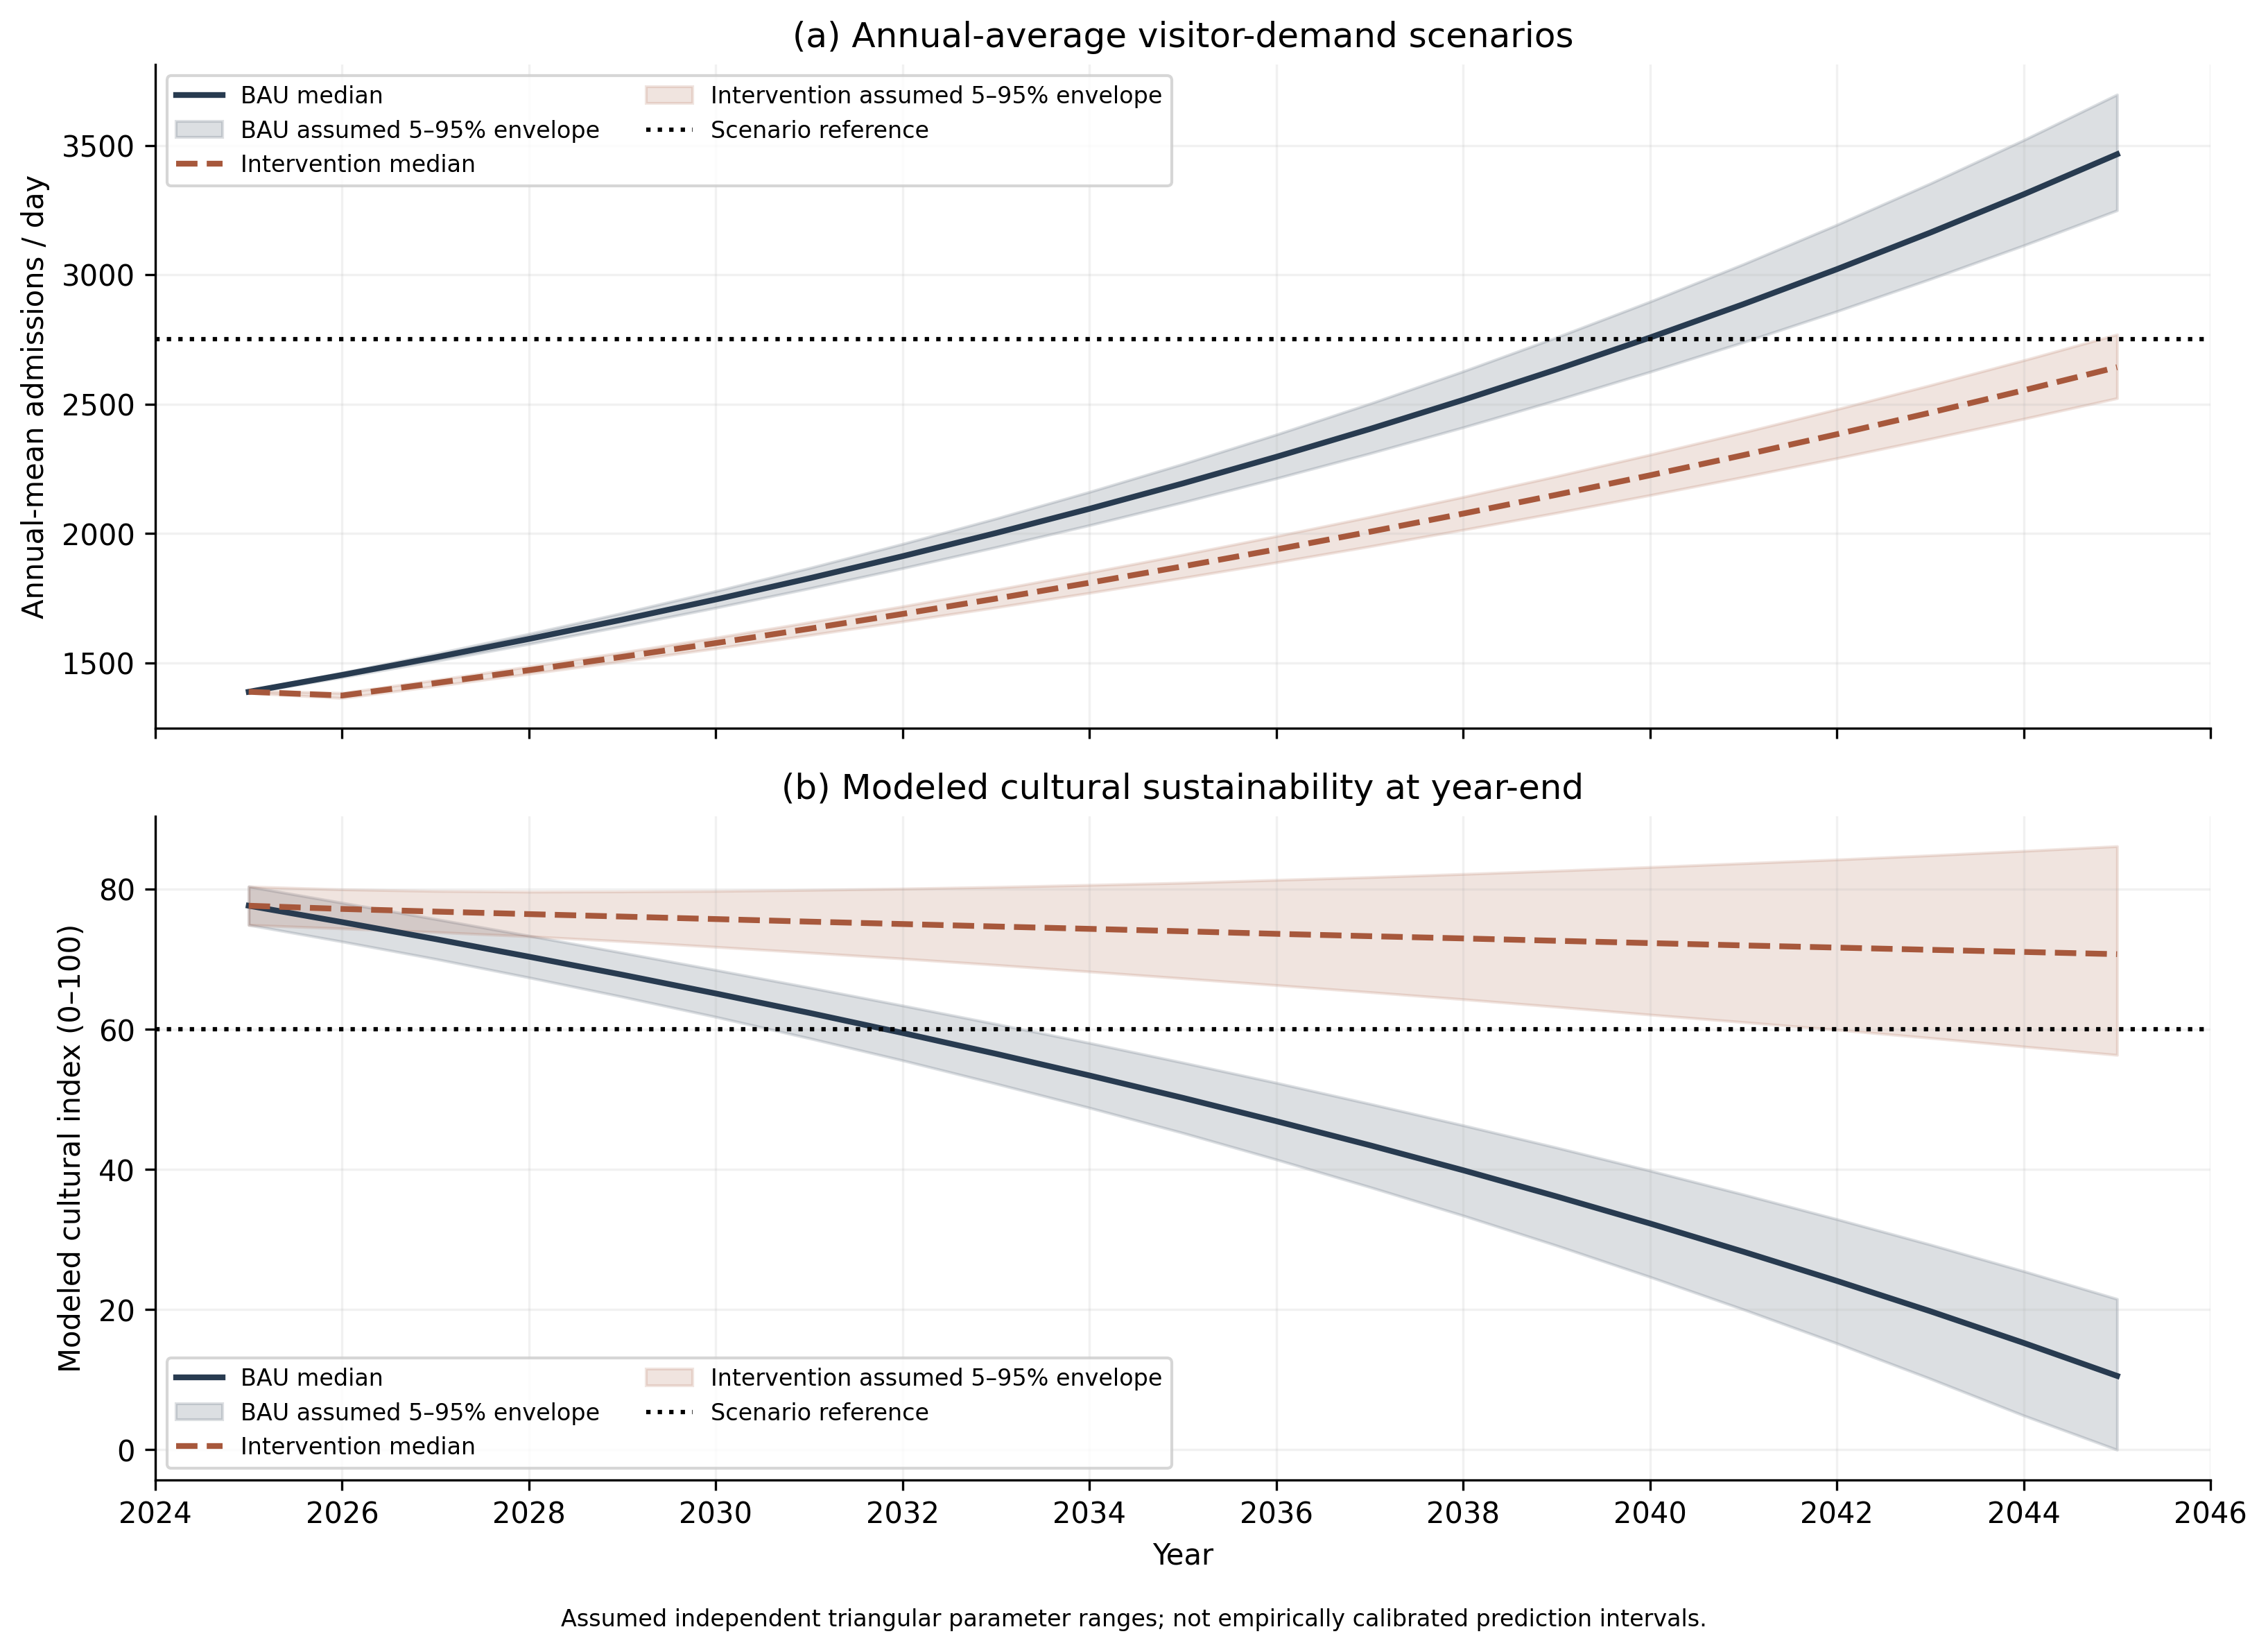

In [2]:
import pandas as pd
import json
from IPython.display import display, Image
baseline_draws, baseline_traj=simulate(1, 0, stochastic=False)
baseline=describe(baseline_draws)
assert baseline['bau_visitor']['earliest_crossing_year']==2040
assert baseline['bau_culture']['earliest_crossing_year']==2032
assert baseline['intervention_visitor']['not_crossed_by_2045']==1
assert baseline['intervention_culture']['not_crossed_by_2045']==1
print('Deterministic baseline matches approved Figures 6a and 8b.')
display(pd.DataFrame(summary).T)
display(Image(filename=str(output/'assumption_conditioned_mc_envelopes.png')))


In [3]:
print('Executing 10,000 uniform-range comparison draws ...')
uniform_draws, uniform_trajectories=simulate(N, SEED, distribution='uniform')
uniform_summary=describe(uniform_draws)
for label, result in uniform_summary.items():print(label,result)


Executing 10,000 uniform-range comparison draws ...


bau_visitor {'n': 10000, 'crossed_by_2045': 10000, 'not_crossed_by_2045': 0, 'crossing_share_pct': 100.0, 'crossing_year_p05_conditional': 2039.0, 'crossing_year_median_conditional': 2040.0, 'crossing_year_p95_conditional': 2042.0, 'earliest_crossing_year': 2039, 'latest_crossing_year': 2042}
intervention_visitor {'n': 10000, 'crossed_by_2045': 1933, 'not_crossed_by_2045': 8067, 'crossing_share_pct': 19.33, 'crossing_year_p05_conditional': 2045.0, 'crossing_year_median_conditional': 2045.0, 'crossing_year_p95_conditional': 2045.0, 'earliest_crossing_year': 2044, 'latest_crossing_year': 2045}
bau_culture {'n': 10000, 'crossed_by_2045': 10000, 'not_crossed_by_2045': 0, 'crossing_share_pct': 100.0, 'crossing_year_p05_conditional': 2031.0, 'crossing_year_median_conditional': 2032.0, 'crossing_year_p95_conditional': 2034.0, 'earliest_crossing_year': 2030, 'latest_crossing_year': 2037}
intervention_culture {'n': 10000, 'crossed_by_2045': 1978, 'not_crossed_by_2045': 8022, 'crossing_share_pct

In [4]:
# Save machine-readable data and model-assumption checks (including non-crossing draws).
draws.to_csv(output/'assumption_conditioned_mc_draws.csv',index=False)
trajectories.to_csv(output/'assumption_conditioned_mc_trajectories.csv',index=False)
uniform_draws.to_csv(output/'assumption_conditioned_mc_uniform_draws.csv',index=False)
uniform_trajectories.to_csv(output/'assumption_conditioned_mc_uniform_trajectories.csv',index=False)
result={'n':N,'seed':SEED,'interpretation':'assumed independent ranges, not empirical confidence intervals',
        'triangular':summary,'uniform':uniform_summary}
(output/'MC_Results_Both_Distributions.json').write_text(json.dumps(result,indent=2)+'\n')
print('Saved all files to',output)


Saved all files to /mnt/data/atr_monte_carlo_package/reproducibility/outputs/monte-carlo-2026-11-13
